# Results and error analysis

Inputs: `results/runs.csv` (W&B export), `results/predictions/*.csv` (from `scripts/evaluate.py`), `results/edit_types_validation.csv` (Claude labels, validation only).

Error analysis uses validation; test is only reported.

In [1]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from art_nlp.data import load_split

FIG = Path('../results/figures'); FIG.mkdir(parents=True, exist_ok=True)
runs = pd.read_csv('../results/runs.csv')
runs['variant'] = runs.apply(lambda r: f"{r.model}-{'hyponly' if r.get('hyp_only') is True else r.format}"
    + ('-ix' if r.model == 'bag' and r.interactions is True else '')
    + (f"-{r.cell}" if r.model == 'rnn' else '') + ('-bi' if r.model == 'rnn' and r.bidirectional is True else ''), axis=1)
plt.rcParams.update({'font.size': 13, 'axes.spines.top': False, 'axes.spines.right': False})
LABEL = {'bag-hyponly': 'Hypothesis only', 'bag-score-ix': 'Model 1: avg. embeddings', 'rnn-score-gru-bi': 'Model 2: bi-GRU'}
COLOR = {'bag-hyponly': '#9aa3b2', 'bag-score-ix': '#2f5fd0', 'rnn-score-gru-bi': '#e07b28'}
SWEEP = {'bag-score-ix': ('M1 score + interactions', '#2f5fd0', '-'), 'bag-score': ('M1 score', '#86a3e8', '-'),
         'bag-concat': ('M1 concat', '#86a3e8', ':'), 'rnn-score-gru-bi': ('M2 bi-GRU', '#e07b28', '-'),
         'rnn-score-gru': ('M2 GRU', '#f0b07a', '-'), 'rnn-score-lstm': ('M2 LSTM', '#c9a27f', '-'),
         'rnn-concat-gru': ('M2 concat (GRU, LSTM)', '#f0b07a', ':')}
len(runs)

/Users/marvin/VSCode/nlp-hs26-art/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


70

## Sweeps: learning rate per variant (best validation loss)

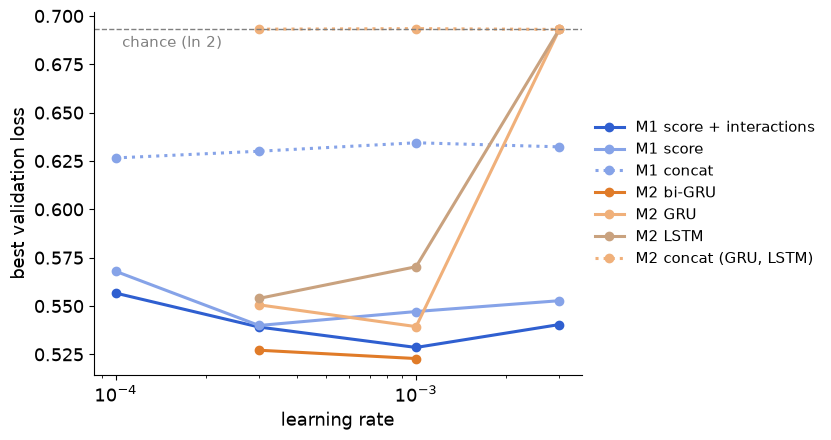

In [2]:
tags = runs.tags.fillna('')
sw = runs[tags.str.contains('sweep') & ~tags.str.contains('ablation')]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for v, (lab, col, ls) in SWEEP.items():
    g = sw[sw.variant == v].groupby('lr')['best/val/loss'].min()
    ax.plot(g.index, g.values, marker='o', c=col, ls=ls, lw=2.2, label=lab)
ax.axhline(0.6931, ls='--', c='grey', lw=1); ax.text(1.05e-4, 0.684, 'chance (ln 2)', color='grey', fontsize=11)
ax.set(xscale='log', xlabel='learning rate', ylabel='best validation loss')
ax.legend(fontsize=10.5, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5)); fig.tight_layout()
fig.savefig(FIG / 'lr_sweep.png', dpi=200); plt.show()

In [3]:
sw.groupby('variant')[['best/val/loss', 'best/val/acc']].agg(['min', 'max', 'count']).round(3)

best/val/loss              best/val/acc             
                           min    max count          min    max count
variant                                                              
bag-concat               0.627  0.640     8        0.626  0.663     8
bag-score                0.540  0.603     8        0.660  0.727     8
bag-score-ix             0.529  0.579     8        0.709  0.734     8
rnn-concat-gru           0.693  0.693     3        0.489  0.508     3
rnn-concat-lstm          0.693  0.693     3        0.508  0.508     3
rnn-score-gru            0.539  0.693     7        0.565  0.729     7
rnn-score-gru-bi         0.523  0.551     4        0.719  0.745     4
rnn-score-lstm           0.554  0.693     3        0.527  0.718     3

## Ablations: one setting changed from the final configs (validation)

In [4]:
ab = runs[runs.tags.fillna('').str.contains('ablation|final')].copy()
ab['embedding'] = ab.embeddings.str.extract(r'/([a-z]+)-')[0]
cols = ['model', 'embedding', 'hidden', 'dropout', 'batch_size', 'lr']
ab.groupby(cols)[['best/val/loss', 'best/val/acc']].agg(['mean', 'std', 'count']).round(4)

best/val/loss                \
                                                          mean     std count   
model embedding hidden dropout batch_size lr                                   
bag   fasttext  512    0.2     64         0.0010        0.5179  0.0027     3   
      glove     512    0.0     64         0.0010        0.5665     NaN     1   
                       0.2     32         0.0010        0.5317     NaN     1   
                               64         0.0010        0.5281  0.0018     3   
                               128        0.0010        0.5301     NaN     1   
                       0.5     64         0.0010        0.5313     NaN     1   
rnn   fasttext  256    0.5     64         0.0010        0.5939  0.0860     3   
      glove     128    0.5     64         0.0010        0.5381     NaN     1   
                256    0.2     64         0.0003        0.5324  0.0067     3   
                       0.5     32         0.0010        0.5482     NaN     1   
                               64         0.0010        0.5346  0.0116     3   
                               128        0.0010        0.5470     NaN     1   
                512    0.5     64         0.0010        0.5458     NaN     1   

                                                 best/val/acc                
                                                         mean     std count  
model embedding hidden dropout batch_size lr                                 
bag   fasttext  512    0.2     64         0.0010       0.7533  0.0061     3  
      glove     512    0.0     64         0.0010       0.7110     NaN     1  
                       0.2     32         0.0010       0.7380     NaN     1  
                               64         0.0010       0.7357  0.0067     3  
                               128        0.0010       0.7490     NaN     1  
                       0.5     64         0.0010       0.7320     NaN     1  
rnn   fasttext  256    0.5     64         0.0010       0.6463  0.0949     3  
      glove     128    0.5     64         0.0010       0.7240     NaN     1  
                256    0.2     64         0.0003       0.7367  0.0085     3  
                       0.5     32         0.0010       0.7180     NaN     1  
                               64         0.0010       0.7397  0.0076     3  
                               128        0.0010       0.7300     NaN     1  
                512    0.5     64         0.0010       0.7160     NaN     1

## Final models: three seeds

In [5]:
fin = runs[runs.tags.fillna('').str.contains('final|baseline')]
summary = fin.groupby('variant')['best/val/acc'].agg(['mean', 'std', 'count']).round(4)
summary

,mean,std,count
variant,,,
bag-hyponly,0.6930,0.0020,3
bag-score-ix,0.7357,0.0067,3
rnn-score-gru-bi,0.7397,0.0076,3


## Test accuracy (single evaluation of the final checkpoints)

In [6]:
def preds(split):
    out = {}
    for f in sorted(Path('../results/predictions').glob(f'*-{split}.csv')):
        out[f.name.removesuffix(f'-{split}.csv')] = pd.read_csv(f)
    return out

val, test = preds('validation'), preds('test')
name2var = dict(zip(runs.name, runs.variant))
acc = pd.DataFrame([dict(variant=name2var.get(n, n), run=n, split=s, acc=(p.pred == p.label).mean())
                    for s, d in (('validation', val), ('test', test)) for n, p in d.items()])
table = acc.groupby(['variant', 'split']).acc.agg(['mean', 'std']).unstack().round(4)
table

mean                std           
split               test validation    test validation
variant                                               
bag-hyponly       0.5220     0.6930  0.0040     0.0020
bag-score-ix      0.5346     0.7357  0.0041     0.0067
rnn-score-gru-bi  0.5453     0.7397  0.0062     0.0076

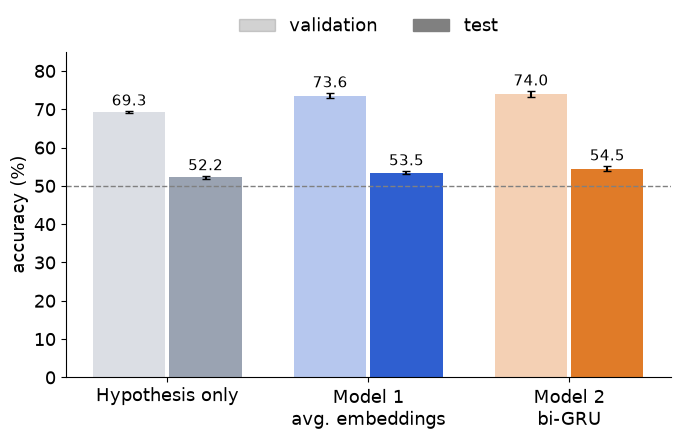

In [7]:
t = acc.groupby(['variant', 'split']).acc.agg(['mean', 'std']).mul(100)
order = ['bag-hyponly', 'bag-score-ix', 'rnn-score-gru-bi']
fig, ax = plt.subplots(figsize=(7, 4.6))
for i, v in enumerate(order):
    for j, (s, alpha) in enumerate((('validation', 0.35), ('test', 1.0))):
        m, sd = t.loc[(v, s)]
        ax.bar(i + (j - 0.5) * 0.38, m, 0.36, yerr=sd, color=COLOR[v], alpha=alpha, capsize=3)
        ax.text(i + (j - 0.5) * 0.38, m + sd + 1.5, f'{m:.1f}', ha='center', fontsize=11)
ax.axhline(50, ls='--', c='grey', lw=1)
ax.set_xticks(range(3), [LABEL[v].replace(': ', '\n') for v in order])
ax.set(ylabel='accuracy (%)', ylim=(0, 85))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='grey', alpha=a) for a in (0.35, 1)], labels=['validation', 'test'],
          frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncols=2)
fig.tight_layout(); fig.savefig(FIG / 'val_vs_test.png', dpi=200); plt.show()

## Why is test harder? Size of the edit between the two hypotheses (label-free)

In [8]:
tok = lambda t: re.findall(r"\w+|[^\w\s]", t.lower())
def diff_bucket(split):
    d = [len(set(tok(e.hyps[0])) ^ set(tok(e.hyps[1]))) for e in load_split(split)]
    return pd.cut(pd.Series(d), [-1, 4, 8, 12, 100], labels=['0-4', '5-8', '9-12', '13+'])
buckets = {'validation': diff_bucket('validation'), 'test': diff_bucket('test')}
rows = []
for s, d in (('validation', val), ('test', test)):
    for n, p in d.items():
        for b, g in p.groupby(buckets[s]):
            rows.append(dict(variant=name2var.get(n, n), split=s, words_differing=b, acc=(g.pred == g.label).mean(), n=len(g)))
by_diff = pd.DataFrame(rows).groupby(['variant', 'split', 'words_differing'], observed=True).agg(acc=('acc', 'mean'), n=('n', 'first')).round(3)
by_diff.unstack('words_differing').reindex(columns=['0-4', '5-8', '9-12', '13+'], level=1)

acc                         n               
words_differing                0-4    5-8   9-12    13+  0-4  5-8 9-12  13+
variant          split                                                     
bag-hyponly      test        0.577  0.529  0.504  0.523   97  174  429  832
                 validation  0.695  0.694  0.670  0.707  606  253   91   50
bag-score-ix     test        0.591  0.519  0.511  0.543   97  174  429  832
                 validation  0.753  0.739  0.630  0.700  606  253   91   50
rnn-score-gru-bi test        0.560  0.592  0.538  0.537   97  174  429  832
                 validation  0.734  0.765  0.659  0.820  606  253   91   50

## Error analysis on validation by edit type

In [9]:
edits = pd.read_csv('../results/edit_types_validation.csv')
rows = []
for n, p in val.items():
    m = p.merge(edits, on='idx')
    m['correct'] = m.pred == m.label
    for key in ('edit_type', 'absurd_alone'):
        for v, g in m.groupby(key):
            rows.append(dict(variant=name2var.get(n, n), group=f'{key}={v}', acc=g.correct.mean(), n=len(g)))
by_edit = pd.DataFrame(rows).groupby(['group', 'variant']).agg(acc=('acc', 'mean'), n=('n', 'first')).acc.unstack().round(3)
by_edit['n'] = pd.DataFrame(rows).groupby('group').n.first()
by_edit

variant,bag-hyponly,bag-score-ix,rnn-score-gru-bi,n
group,,,,
absurd_alone=False,0.681,0.725,0.729,835
absurd_alone=True,0.754,0.790,0.794,165
edit_type=action,0.653,0.728,0.735,200
edit_type=entity,0.644,0.717,0.666,313
edit_type=negation,0.786,0.783,0.832,129
edit_type=other,0.688,0.679,0.751,79
edit_type=outcome,0.755,0.785,0.812,229
edit_type=time_quantity,0.640,0.627,0.633,50


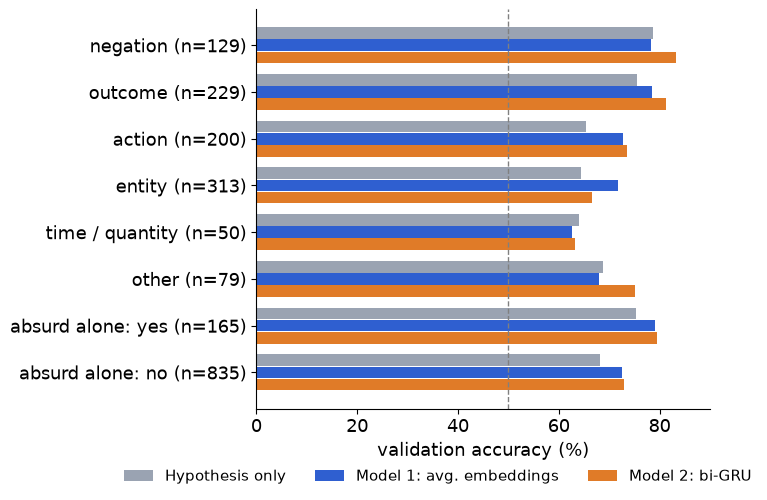

In [10]:
groups = ['edit_type=negation', 'edit_type=outcome', 'edit_type=action', 'edit_type=entity', 'edit_type=time_quantity',
          'edit_type=other', 'absurd_alone=True', 'absurd_alone=False']
names = {g: g.split('=')[1].replace('_', ' / ') for g in groups}
names.update({'absurd_alone=True': 'absurd alone: yes', 'absurd_alone=False': 'absurd alone: no'})
fig, ax = plt.subplots(figsize=(7.5, 5.2))
for k, v in enumerate(['bag-hyponly', 'bag-score-ix', 'rnn-score-gru-bi']):
    ax.barh([i + (k - 1) * 0.26 for i in range(len(groups))], by_edit.loc[groups, v] * 100, 0.25, color=COLOR[v], label=LABEL[v])
ax.set_yticks(range(len(groups)), [f"{names[g]} (n={by_edit.loc[g, 'n']})" for g in groups]); ax.invert_yaxis()
ax.axvline(50, ls='--', c='grey', lw=1); ax.set(xlabel='validation accuracy (%)', xlim=(0, 90))
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.4, -0.12), ncols=3, fontsize=10.5)
fig.tight_layout(); fig.savefig(FIG / 'edit_types.png', dpi=200); plt.show()

## Example errors of the best RNN (validation)

In [11]:
data = load_split('validation')
rnn_runs = [n for n in val if name2var.get(n, '').startswith('rnn')]
p = val[rnn_runs[0]].merge(edits, on='idx')
wrong = p[p.pred != p.label].assign(conf=lambda d: (d.prob_h2 - 0.5).abs()).nlargest(8, 'conf')
for _, r in wrong.iterrows():
    e = data[r.idx]
    print(f"[{r.edit_type}] {e.obs1} | +{e.hyps[e.label]} | -{e.hyps[1 - e.label]} | {e.obs2}")

[outcome] May was a science teacher at a local high school. | +May was a distant and uninvolved teacher. | -May was a caring teacher. | She handed out assignments and browsed the internet all day.
[time_quantity] When I was younger my family and I would go on summer vacations. | +Lately, my family hardly talks to each other. | -Lately, my family talks to each other constantly. | Now every time summer comes around I become sad.
[outcome] Megan is the new boss at her office. | +Megan relaxed the dress code at work. | -Megan made a strict dress code. | She instantly became very well liked by the staff.
[entity] In August Billy is going overseas for the war. | +Bill made it overseas to fight the war. | -Bill made it overseas to the wedding. | Now Bill only focuses on the war, and serving his country.
[action] When my phone rang I just knew something was wrong. | +my sister needed a ride home from a bad date. | -my sister needed a break from a a job. | She was so surprised and happy to see 